In [1]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
# sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi
import matplotlib

In [3]:
prefix = '/mnt/staging/'
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(FIGURES / "figure5") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"
figure_config_root = str(PREPARES / "config") + "/"

data_root =  str(PREPARES / "epochs-rest-to-running") + "/"
mouse='cm125'

In [4]:
M2_ind = load_pickle(fetch_path_M2+'brightest_frontline_ind-'+mouse)
sensory_ind = load_pickle(fetch_path_S1+'inferred_brightest_ind_'+mouse)
extra_ind = load_pickle(fetch_path_extra+'extra_ind_'+mouse)
extra_extra_ind = load_pickle(fetch_path_extra+'extra_extra_ind_'+mouse)
sensory_ind['RM']=extra_extra_ind['right_mouth_sensory']
sensory_ind['LM']=sensory_ind['mouth']
sensory_ind['LV']=extra_ind['LV']
sensory_ind['RV']=extra_ind['RV']

M2_ind['RM']=extra_extra_ind['right_mouth_motor']
M2_ind['LM']=M2_ind['mouth']

/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_35604/407771601.py:7: RuntimeWarning: invalid value encountered in cast
  props = regionprops(IDX_sorted.astype(int))


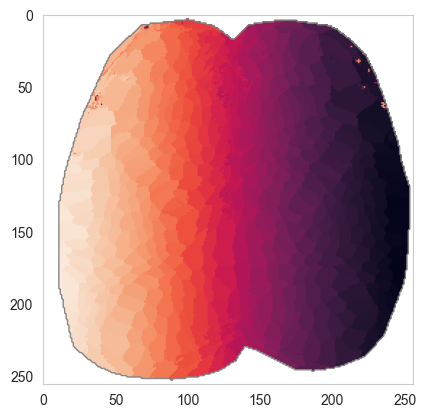

In [5]:
with h5py.File(step_0_root+mouse+'/idx_sorted_500_'+mouse+'.mat','r') as f_idx:
    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
    
    mask = IDX_sorted >0
    mask = mask.astype(float)
    mask[mask==0]='nan'
    
from skimage import measure
brain_contours = measure.find_contours(mask>-100, level=0.5)
for contour in brain_contours:
    plt.plot(contour[:,1],contour[:,0],linewidth=1,color='gray',alpha=0.9)
        
    
plt.imshow(IDX_sorted)

In [6]:
palatte_dict = load_pickle(figure_config_root+'palatte_dict')
# for S1 homunculus
palatte_dict['mouth']=palatte_dict['RM']
palatte_dict['nose']=palatte_dict['RN']
palatte_dict['LV'] = '#ee8c7d'
palatte_dict['tail'] = 'palegreen'

sunset_cmap = load_pickle(figure_config_root+'sunset_cmap')

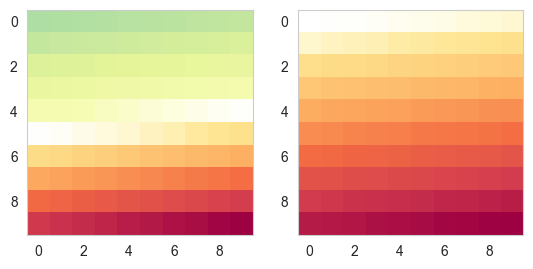

In [7]:
import matplotlib.colors as colors

def truncate_colormap(cmap, minval=0.0, maxval=1.0, n=100):
    new_cmap = colors.LinearSegmentedColormap.from_list(
        'trunc({n},{a:.2f},{b:.2f})'.format(n=cmap.name, a=minval, b=maxval),
        cmap(np.linspace(minval, maxval, n)))
    return new_cmap

arr = np.linspace(0, 50, 100).reshape((10, 10))
fig, ax = plt.subplots(ncols=2)


cmap = plt.get_cmap('Spectral_r')
sunset_above_cmap = truncate_colormap(sunset_cmap, 0.5, 1)

ax[0].imshow(arr, interpolation='nearest', cmap=sunset_cmap)
ax[1].imshow(arr, interpolation='nearest', cmap=sunset_above_cmap)
plt.show()

In [8]:
fetch_path_contours = str(PREPARES / "heterogeneity-contours") + "/"

clean_contours_M2=load_pickle(fetch_path_contours+'clean_contours_'+'cm125')
clean_contours_S1 = load_pickle(fetch_path_contours+'clean_contours_S1_'+'cm125')

# clean_contours_M2_fit = load_pickle(fetch_path_contours+'clean_contours_fit_'+mouse)


**load rest-running bouts data**

In [9]:
load_list = ['norm_M_jrgeco', 'norm_M_rotf', 'norm_M_face_pc', 'norm_M_body_pc', 'norm_M_pupil_pc_norm', 
 'norm_M_whisk_vel_norm', 'norm_M_nose_vel_norm', 'norm_M_LFP_vel_norm', 'norm_M_RFP_vel_norm',
 'M_day_label', 'M_is_groom', 'M_ind', 'norm_M_mirrorRFP_vel_norm', 'norm_M_mirrorLFP_vel_norm', 
 'norm_M_mirrorRHP_vel_norm', 'norm_M_mirrorLHP_vel_norm']

fetch_path_all_seed = str(PREPARES / "epochs-rest-to-running") + "/"


f = scipy.io.loadmat(fetch_path_all_seed+'final_'+mouse+'_norm.mat')

for item in load_list:
    exec("{}=np.squeeze(f['{}'])".format(item,item))
T_PRE=200;
T_POST=300;
T=T_PRE+T_POST

# zscore first
norm_M_jrgeco_zscore = norm_M_jrgeco.copy()
norm_M_jrgeco_zscore = stats.zscore(norm_M_jrgeco_zscore,axis=1)
ss = norm_M_jrgeco.shape
norm_M_jrgeco_zscore_std = np.empty((ss[0],ss[1],0))
for i_bout in range(ss[2]):
    temp = pd.DataFrame(norm_M_jrgeco_zscore[:,:,i_bout]).T.rolling(20).std().T.values
    norm_M_jrgeco_zscore_std=np.append(norm_M_jrgeco_zscore_std,temp[:,:,np.newaxis],axis=2)


In [10]:
fetch_path_all_seed = str(PREPARES / "heterogeneity/all-seed") + "/"

bdp_w_order = ['LFP','RFP','LHP','RHP','LM','RM','LW','RW','LN','RN','LV','RV','LT','RT']
with h5py.File(fetch_path_all_seed+'cm125_all_corr_maps_dict.h5', 'r') as hf:
    corr_maps_dict={}
    for i in range(len(bdp_w_order)):
        bdp=bdp_w_order[i]
        region_number = sensory_ind[bdp]
        corr_maps_dict[bdp+'-sensory'] = np.array(hf['roi-'+str(region_number)])

In [11]:
palatte_dict['LT'] =  '#c4afaf' #'#b3b3b3'
palatte_dict['RT']  = '#e4c494' ##b69d76 back up


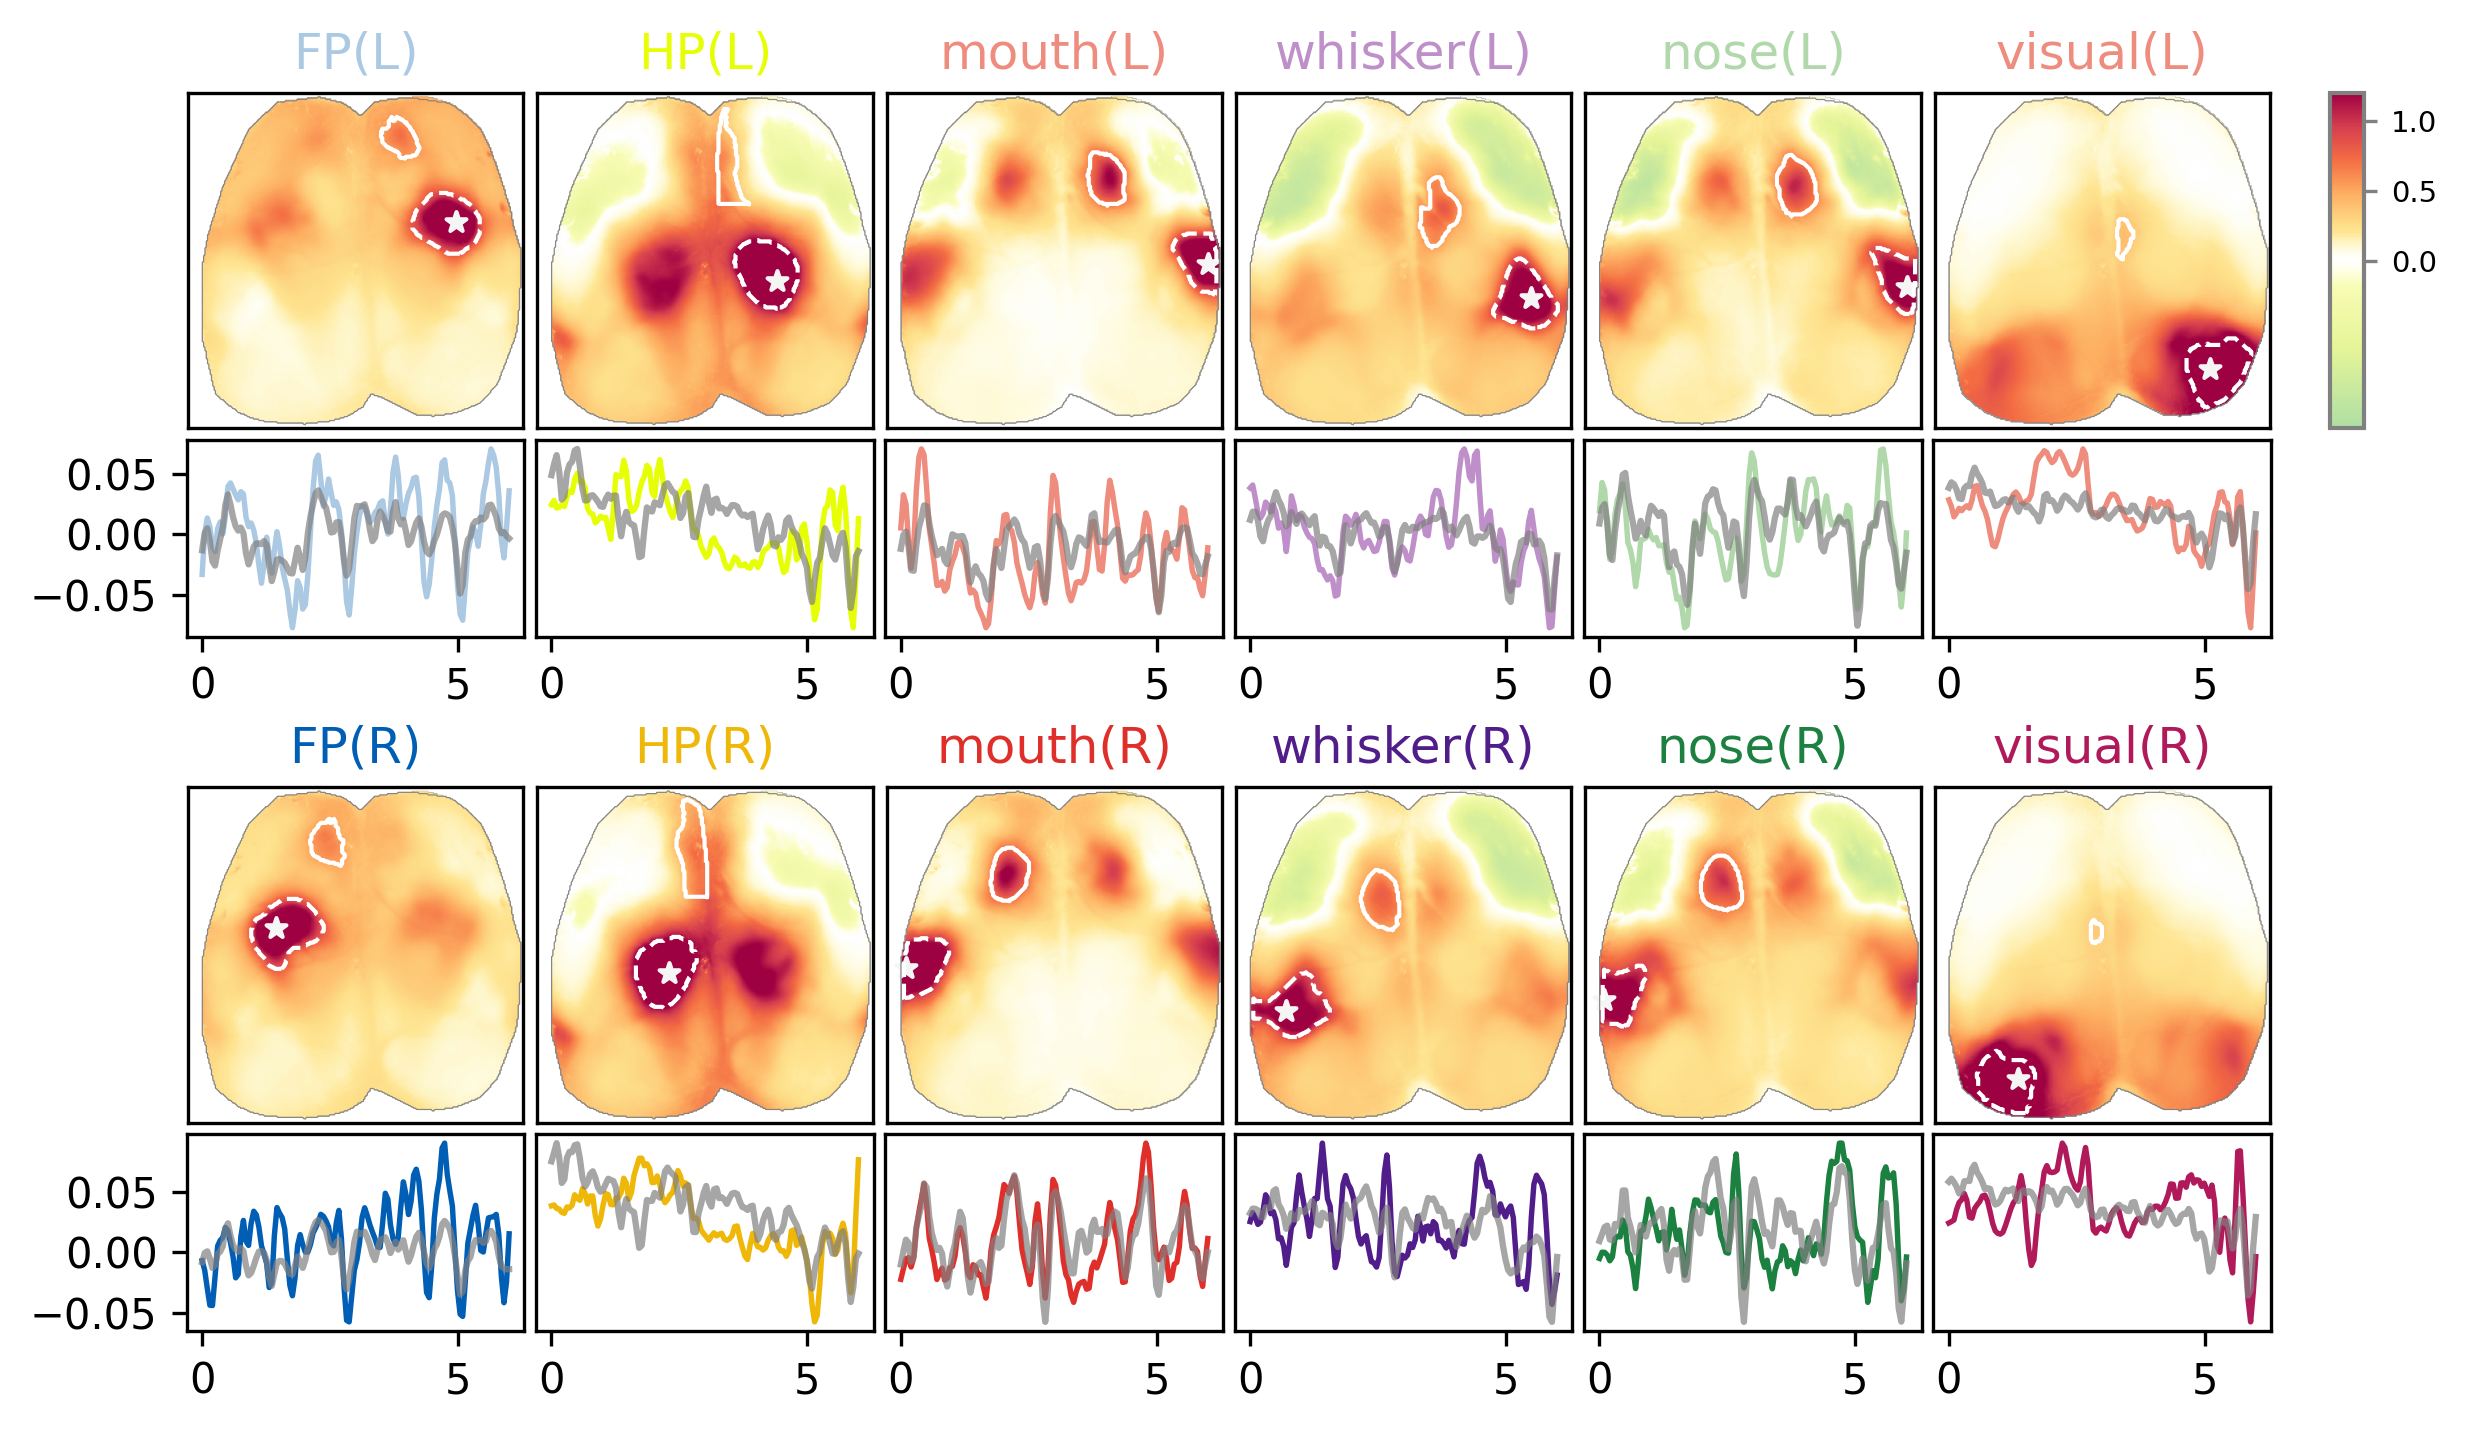

In [14]:
# from sciplotlib import style as spstyle
# from sciplotlib import polish as sppolish
from matplotlib.gridspec import GridSpec
from skimage import measure
from matplotlib import ticker
import matplotlib
plt.style.use('default')
from matplotlib import colors
gs = GridSpec(100,100)
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;y_gap=1;x_gap=0;x_width=5

x_start = x_offset
for i_ax in range(6):
    exec("ax{} = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_start+5])".format(i_ax))
    x_start = x_start+5+x_gap
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))
x_start = x_offset
for i_ax in range(6,12):
    exec("ax{} = fig.add_subplot(gs[y_offset+10:y_offset+15,x_start:x_start+5])".format(i_ax))
    x_start = x_start+5+x_gap
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xticks([])".format(i_ax))    
    
    
x_start = x_offset
for i_ax in range(12,18):
    exec("ax{} = fig.add_subplot(gs[y_offset+5:y_offset+8,x_start:x_start+5])".format(i_ax))
    x_start = x_start+5+x_gap
    if i_ax > 12:
        exec("ax{}.set_yticks([])".format(i_ax))

x_start = x_offset
for i_ax in range(18,24):
    exec("ax{} = fig.add_subplot(gs[y_offset+15:y_offset+18,x_start:x_start+5])".format(i_ax))
    x_start = x_start+5+x_gap
    if i_ax > 18:
        exec("ax{}.set_yticks([])".format(i_ax))
    
ax99 = fig.add_subplot(gs[y_offset:y_offset+5,x_start:x_start+2])


bdp_short_dict = {'LFP':'FP(L)','LHP':'HP(L)','LM':'mouth(L)','LW':'whisker(L)',
                  'LN':'nose(L)','RFP':'FP(R)','RHP':'HP(R)','RM':'mouth(R)',
                  'RW':'whisker(R)','RN':'nose(R)','LV':'visual(L)','RV':'visual(R)',
                 'RT':'tail(R)','LT':'tail(L)'}
bdp_w_order = ['LFP','LHP','LM','LW','LN','LV','RFP','RHP','RM','RW','RN','RV']
divnorm=colors.TwoSlopeNorm(vmin=-0.2, vcenter=0., vmax=1.2)
for i in range(12):
    bdp=bdp_w_order[i]
    region_number = sensory_ind[bdp]
    exec("sbp{}=ax{}.imshow(np.arctanh(corr_maps_dict[bdp+'-sensory']),cmap=sunset_cmap,norm=divnorm)".format(i,i))
    exec("title_here = ax{}.set_title(bdp_short_dict[bdp],color=palatte_dict[bdp])".format(i))
    exec("ax{}.scatter(node_coords[region_number,1], node_coords[region_number,0], marker='*', s=25, c='whitesmoke', zorder=2)".format(i))

    # if bdp in ['LHP','RHP','LT','RT']:
    #     for contour in clean_contours_M2_fit[bdp]:
    #         exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=1,color='white',alpha=1)".format(i))
    # else:
    for contour in clean_contours_M2[bdp]:
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=1,color='white',alpha=1)".format(i))

    for contour in clean_contours_S1[bdp]:
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=1,linestyle='dashed',color='white',alpha=1)".format(i))
    for contour in brain_contours:
        exec("ax{}.plot(contour[:,1],contour[:,0],linewidth=0.3,color='gray',alpha=0.9)".format(i))
            
cb = fig.colorbar(sbp7, cax=ax99,fraction=0.5,orientation='vertical');
cb.ax.tick_params(labelsize=7,length=3,color='gray')
cb.ax.yaxis.tick_right() 

cb.outline.set_edgecolor('gray')
cb.outline.set_linewidth(1)
tick_locator = ticker.MaxNLocator(nbins=3)
cb.locator = tick_locator
cb.update_ticks()

ax99.set_aspect(10)


i_bout = 16
t_stop_here = 120
x_here=np.linspace(0,t_stop_here,t_stop_here)
my_xticks_here = np.divide(x_here,20)
for i in range(12):
    bdp=bdp_w_order[i]
    S1_region_number = sensory_ind[bdp]
    M2_region_number = M2_ind[bdp]
    exec("plot_here = ax{}.plot(my_xticks_here,norm_M_jrgeco[S1_region_number,:t_stop_here,i_bout],label='S1',linewidth=1.3,color=palatte_dict[bdp])".format(i+12))
    exec("ax{}.plot(my_xticks_here,norm_M_jrgeco[M2_region_number,:t_stop_here,i_bout],label='M2',color='gray',linewidth=1.5,alpha=0.7)".format(i+12))


vals = ax14.get_yticks()
ax14.set_yticklabels(['{:,.0%}'.format(x) for x in vals])
vals = ax21.get_yticks()
ax21.set_yticklabels(['{:,.0%}'.format(x) for x in vals])

# ax27.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize=6)

plt.savefig('fig3-resting-heterogeneity.svg',format='svg',dpi=300)